In [2]:
import kagglehub
import os
import pandas as pd

dataset_path = kagglehub.dataset_download("prosperchuks/health-dataset")
df_stroke = pd.read_csv(os.path.join(dataset_path, "stroke_data.csv"))

print("Total rows:", len(df_stroke))
print("Exact duplicate rows:", df_stroke.duplicated().sum())
print("Unique rows (excluding age/sex):", df_stroke.drop(columns=['sex'], errors='ignore').drop_duplicates().shape[0])
print("\nMissing values:\n", df_stroke.isna().sum())
print("\nTarget balance:\n", df_stroke['stroke'].value_counts(normalize=True))

Total rows: 40910
Exact duplicate rows: 0
Unique rows (excluding age/sex): 33919

Missing values:
 sex                  3
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64

Target balance:
 stroke
1    0.500122
0    0.499878
Name: proportion, dtype: float64


In [4]:
df_stroke.head()

,sex,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,1.0,63.0,0,1,1,4,1,228.69,36.6,1,1
1,1.0,42.0,0,1,1,4,0,105.92,32.5,0,1
2,0.0,61.0,0,0,1,4,1,171.23,34.4,1,1
3,1.0,41.0,1,0,1,3,0,174.12,24.0,0,1
4,1.0,85.0,0,0,1,4,1,186.21,29.0,1,1


In [ ]:
# 1. Check linear correlation of age and sex with stroke
print(df_stroke[['age', 'sex', 'stroke']].corr()['stroke'])

# 2. Check if identical patients (same exact glucose & bmi) were given wildly different ages
sample_clones = df_stroke[df_stroke.duplicated(subset=['avg_glucose_level', 'bmi', 'hypertension'], keep=False)]
print(sample_clones.sort_values(by=['avg_glucose_level', 'bmi'])[['age', 'sex', 'avg_glucose_level', 'bmi', 'stroke']].head(10))

age       0.058534
sex      -0.111036
stroke    1.000000
Name: stroke, dtype: float64
        age  sex  avg_glucose_level   bmi  stroke
23557  47.0  1.0              55.12  21.8       0
26779  33.0  1.0              55.12  21.8       0
29962  73.0  1.0              55.12  21.8       0
33103  53.0  1.0              55.12  21.8       0
36217  41.0  1.0              55.12  21.8       0
39288  74.0  1.0              55.12  21.8       0
21110  51.0  1.0              55.22  27.0       0
24349  42.0  0.0              55.22  27.0       0
27559  63.0  1.0              55.22  27.0       0
30736  39.0  0.0              55.22  27.0       0


In [6]:
# Drop the corrupted columns and deduplicate the remaining patient profiles
clinical_cols = [c for c in df_stroke.columns if c not in ['age', 'sex', 'stroke']]
df_stroke_clean = df_stroke.drop(columns=['age', 'sex']).drop_duplicates(subset=clinical_cols).copy()

print("Clean shape:", df_stroke_clean.shape)
print("\nTrue Target Balance:\n", df_stroke_clean['stroke'].value_counts())
print("\nTrue Target Proportions:\n", df_stroke_clean['stroke'].value_counts(normalize=True))

Clean shape: (3425, 9)

True Target Balance:
 stroke
0    3245
1     180
Name: count, dtype: int64

True Target Proportions:
 stroke
0    0.947445
1    0.052555
Name: proportion, dtype: float64


In [10]:
print(df_stroke_clean.corr()['stroke'].sort_values(ascending=False))

stroke               1.000000
hypertension         0.143626
avg_glucose_level    0.140515
heart_disease        0.138538
ever_married         0.071603
smoking_status       0.035003
bmi                  0.011601
work_type            0.010443
Residence_type       0.005999
Name: stroke, dtype: float64


In [11]:
# Drop the low-signal lifestyle columns, keep BMI for tree splits & interactions
cols_to_drop = ['Residence_type', 'work_type', 'smoking_status']
df_stroke_clean = df_stroke_clean.drop(columns=cols_to_drop)

In [ ]:
#Metabolic_Risk = avg_glucose_level * bmi
df_stroke_clean['Metabolic_Risk'] = df_stroke_clean['avg_glucose_level'] * df_stroke_clean['bmi']

0        8370.054
1        3442.400
2        5890.312
3        4178.880
4        5400.090
           ...   
23700    2036.751
23701    1691.081
23702    5008.000
23703    2539.494
23704    4257.024
Name: Metabolic_Risk, Length: 3425, dtype: float64

<Axes: >

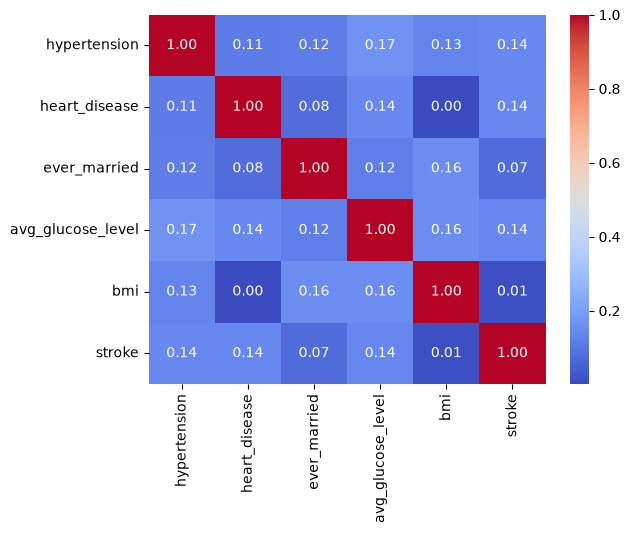

In [12]:
import seaborn as sns

sns.heatmap(df_stroke_clean.corr(), annot=True, cmap='coolwarm', fmt=".2f")

In [14]:
from sklearn.model_selection import train_test_split

X= df_stroke_clean.drop(columns=['stroke'])
y= df_stroke_clean['stroke']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


In [15]:
# Option 1: Glucose amplified by Heart Disease
X_train['Glucose_Heart_Risk'] = X_train['avg_glucose_level'] * (X_train['heart_disease'] + 1)
X_test['Glucose_Heart_Risk'] = X_test['avg_glucose_level'] * (X_test['heart_disease'] + 1)

# Option 2: Total Vascular Burden (combines top 3 predictors: glucose, hypertension, and heart disease)
X_train['Vascular_Risk'] = X_train['avg_glucose_level'] * (1 + X_train['heart_disease'] + X_train['hypertension'])
X_test['Vascular_Risk'] = X_test['avg_glucose_level'] * (1 + X_test['heart_disease'] + X_test['hypertension'])

In [16]:
X_train.head()

,hypertension,heart_disease,ever_married,avg_glucose_level,bmi,Metabolic_Risk,Glucose_Heart_Risk,Vascular_Risk
22707,0,0,1,71.32,43.9,3130.948,71.32,71.32
23362,0,0,1,58.64,33.0,1935.120,58.64,58.64
22342,0,0,1,215.81,58.1,12538.561,215.81,215.81
21800,0,0,1,68.44,23.0,1574.120,68.44,68.44
22126,0,0,1,73.60,27.0,1987.200,73.60,73.60


In [17]:
from sklearn.preprocessing import StandardScaler

cols_to_scale = [
    'avg_glucose_level', 
    'bmi', 
    'Metabolic_Risk', 
    'Glucose_Heart_Risk', 
    'Vascular_Risk'
]

scaler = StandardScaler()
X_train[cols_to_scale] = scaler.fit_transform(X_train[cols_to_scale])
X_test[cols_to_scale] = scaler.transform(X_test[cols_to_scale])

In [18]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix

# 1. Balanced Random Forest (keep max_depth low so it doesn't memorize the 5% minority class)
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=5, 
    class_weight='balanced', 
    random_state=42
)
rf_model.fit(X_train, y_train)

# 2. Weighted XGBoost (ratio of negative to positive is ~18.0)
ratio = (y_train == 0).sum() / (y_train == 1).sum()

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    scale_pos_weight=ratio,
    random_state=42
)
xgb_model.fit(X_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [ ]:
from sklearn.metrics import confusion_matrix

confusion_matrix_rf = confusion_matrix(y_test, rf_model.predict(X_test))
confusion_matrix_xgb = confusion_matrix(y_test, xgb_model.predict(X_test))

print("Random Forest Confusion Matrix:\n", confusion_matrix_rf)

print("\nXGBoost Confusion Matrix:\n", confusion_matrix_xgb)

print("\nRandom Forest Classification Report:\n", classification_report(y_test, rf_model.predict(X_test)))
print("\nXGBoost Classification Report:\n", classification_report(y_test, xgb_model.predict(X_test)))



Random Forest Confusion Matrix:
 [[546 103]
 [ 23  13]]

XGBoost Confusion Matrix:
 [[554  95]
 [ 28   8]]

Random Forest Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.84      0.90       649
           1       0.11      0.36      0.17        36

    accuracy                           0.82       685
   macro avg       0.54      0.60      0.53       685
weighted avg       0.92      0.82      0.86       685


XGBoost Classification Report:
               precision    recall  f1-score   support

           0       0.95      0.85      0.90       649
           1       0.08      0.22      0.12        36

    accuracy                           0.82       685
   macro avg       0.51      0.54      0.51       685
weighted avg       0.91      0.82      0.86       685



In [24]:
import pandas as pd

# 1. Create a side-by-side comparison DataFrame (using rf_preds or xgb_preds)
rf_preds = rf_model.predict(X_test)
comparison = pd.DataFrame({
    'Actual (y_test)': y_test,
    'Predicted (y_pred)': rf_preds,
    'Difference (y_test - y_pred)': y_test - rf_preds
}, index=y_test.index)

# 2. Filter only the mistakes (where Actual != Predicted)
errors = comparison[comparison['Actual (y_test)'] != comparison['Predicted (y_pred)']]
print(f"Total mismatches: {len(errors)} out of {len(y_test)}")
print(errors.head(15))

# 3. Inspect the actual patient features for False Positives vs. False Negatives
# False Positives: Actual = 0, Predicted = 1 (Difference == -1)
false_positives = X_test[(y_test == 0) & (rf_preds == 1)]

# False Negatives: Actual = 1, Predicted = 0 (Difference == 1)
false_negatives = X_test[(y_test == 1) & (rf_preds == 0)]

print(f"\nFalse Positives count: {len(false_positives)} | False Negatives count: {len(false_negatives)}")

Total mismatches: 126 out of 685
       Actual (y_test)  Predicted (y_pred)  Difference (y_test - y_pred)
23508                0                   1                            -1
23679                0                   1                            -1
21192                0                   1                            -1
22108                0                   1                            -1
22094                0                   1                            -1
23234                0                   1                            -1
23518                0                   1                            -1
21939                0                   1                            -1
23382                0                   1                            -1
22984                0                   1                            -1
22784                0                   1                            -1
22821                0                   1                            -1
30                

In [27]:
# Get probability of class 1 (Stroke)
rf_probs = rf_model.predict_proba(X_test)[:, 1]


# Lower boundary to 0.33 to reduce False Negatives
rf_preds_04 = (rf_probs >= 0.33).astype(int)

print("Confusion Matrix (0.33 threshold):\n", confusion_matrix(y_test, rf_preds_04))
print("\nClassification Report:\n", classification_report(y_test, rf_preds_04))

Confusion Matrix (0.33 threshold):
 [[275 374]
 [  7  29]]

Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.42      0.59       649
           1       0.07      0.81      0.13        36

    accuracy                           0.44       685
   macro avg       0.52      0.61      0.36       685
weighted avg       0.93      0.44      0.57       685



In [28]:
import numpy as np
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_test, rf_probs)

# Youden's J statistic = Sensitivity (Recall) - False Positive Rate
best_idx = np.argmax(tpr - fpr)
best_threshold = thresholds[best_idx]

print(f"Optimal Threshold: {best_threshold:.3f} | Recall: {tpr[best_idx]:.2f} | FPR: {fpr[best_idx]:.2f}")

Optimal Threshold: 0.373 | Recall: 0.72 | FPR: 0.45


In [29]:
rf_preds_opt = (rf_probs >= 0.373).astype(int)
print(confusion_matrix(y_test, rf_preds_opt))
print(classification_report(y_test, rf_preds_opt))

[[357 292]
 [ 11  25]]
              precision    recall  f1-score   support

           0       0.97      0.55      0.70       649
           1       0.08      0.69      0.14        36

    accuracy                           0.56       685
   macro avg       0.52      0.62      0.42       685
weighted avg       0.92      0.56      0.67       685

